In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as pl
from tqdm.auto import tqdm
from pathlib import Path

In [2]:
# I also need to check how many reads are discarded during cutting / trimming
# I could compare the number of reads in the original fastq files with the number of reads in the trimmed files

In [3]:
DATADIR = Path("../data/")
read_df = pd.read_csv(DATADIR / "mapped_reads/merged_mapping.csv", index_col=0)

/tmp/ipykernel_1633635/902122610.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([rename[t.get_text()] for t in ax.get_yticklabels()])


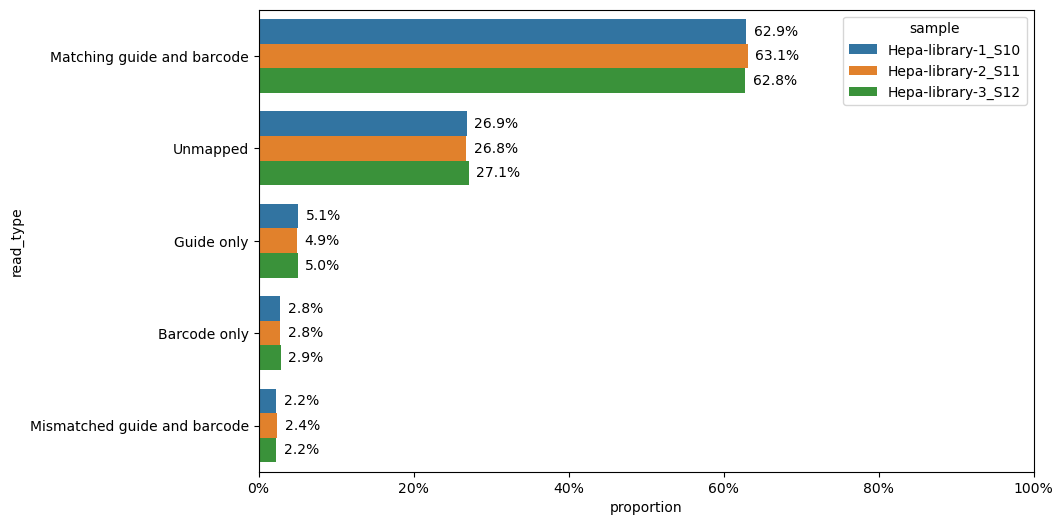

In [4]:
cts = read_df[['sample', 'read_type']].value_counts()
cts = cts.divide(cts.groupby(level=0).sum(), level=0)  # proportions
cts.name = 'proportion'
cts = cts.reset_index()
fig, ax = pl.subplots(figsize=(10, 6))
sns.barplot(data=cts, y='read_type', x='proportion', hue='sample')
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
# add percentage labels to bars
for p in ax.patches:
    width = p.get_width()
    if width > 0.0000001:
        ax.text(width + 0.01, p.get_y() + p.get_height() / 2,
                f'{width:.1%}', ha='left', va='center')
ax.set_xlim(0, 1)
rename = {
    'matching_guide_and_barcode': 'Matching guide and barcode',
    'mismatched_guide_and_barcode': 'Mismatched guide and barcode',
    'guide_only': 'Guide only',
    'barcode_only': 'Barcode only',
    'unmapped': 'Unmapped',
}
ax.set_yticklabels([rename[t.get_text()] for t in ax.get_yticklabels()])
Path("../results/figures").mkdir(parents=True, exist_ok=True)
pl.savefig("../results/figures/read_type_proportions.pdf", bbox_inches='tight')
pl.show()

# Unmapped reads

In [5]:
sample = 'Hepa-library-1_S10'
unmapped_reads = read_df[(read_df.read_type == 'unmapped') & (read_df['sample'] == sample)].index

In [6]:
from Bio import SeqIO
TEMPDIR = Path("../scratch/")
fastq_file = TEMPDIR / f"fastq/{sample}.fastq"

Read M02088:83:000000000-LY4KK:1:1101:10529:3653 Hepa-library-1_S10

FASTQ: GATCGTATTGTTGAAAGGACGAAACACCGTCCCCCTACCAACTGGTCGGGGTTTTCAACCTCTATGCACATCATGTGACCACCAAGTAAACCCC-AACCAAATGGTC-GGGGTTTGAAACCCTTGGCCCCCGAGAATTCCA-GTATTCAGTGAGCCA-GCTTTAAGGCCGGTCC


In [7]:
res = {}
for record in tqdm(SeqIO.parse(fastq_file, "fastq")):
    qual = record.letter_annotations["phred_quality"]
    seq = str(record.seq)
    if record.id in unmapped_reads:
        seq = seq.replace('CCGAGAATTCCA', '_CCGAGAATTCCA-(bc)->')
        seq = seq.replace('GCTTTAAGGCCGG', '<-(bc)-GCTTTAAGGCCGG_')
        seq = seq.replace('GGGGTTTGAAAC', '_GGGGTTTGAAAC-(guide)->')
        seq = seq.replace('CAAGTAAACCCC', '<-(guide)-CAAGTAAACCCC_')
        
        left_guide_constant_present = 'GGGGTTTGAAAC' in seq
        right_guide_constant_present = 'CAAGTAAACCCC' in seq
        left_barcode_constant_present = 'CCGAGAATTCCA' in seq
        right_barcode_constant_present = 'GCTTTAAGGCCGG' in seq
        barcode_right_of_guide = seq.find('(bc)') > seq.find('(guide)') if '(bc)' in seq and '(guide)' in seq else None
        guide_constants_shuffled = seq.find('<-(guide)-') < seq.find('-(guide)->') if left_guide_constant_present and right_guide_constant_present else None
        barcode_constants_shuffled = seq.find('<-(bc)-') < seq.find('-(bc)->') if left_barcode_constant_present and right_barcode_constant_present else None
        
        res[record.id] = {
            'seq': seq,
            'left_guide_constant_present': left_guide_constant_present,
            'right_guide_constant_present': right_guide_constant_present,
            'left_barcode_constant_present': left_barcode_constant_present,
            'right_barcode_constant_present': right_barcode_constant_present,
            'barcode_right_of_guide': barcode_right_of_guide,
            'guide_constants_shuffled': guide_constants_shuffled,
            'barcode_constants_shuffled': barcode_constants_shuffled
        }
info_df = pd.DataFrame(res).T

0it [00:00, ?it/s]

In [12]:
info_df

,seq,left_guide_constant_present,right_guide_constant_present,left_barcode_constant_present,right_barcode_constant_present,barcode_right_of_guide,guide_constants_shuffled,barcode_constants_shuffled
M02088:83:000000000-LY4KK:1:1101:15199:1362,GATTCTTGTTGAACGGACGAAACACCGTACCCCTACCAACTGGTCG...,False,True,False,True,True,None,None
M02088:83:000000000-LY4KK:1:1101:14955:1383,GATTCTTGTGGAACGGACGAAACACCGTACCCCTACCAACTGGTCG...,False,True,False,True,True,None,None
M02088:83:000000000-LY4KK:1:1101:12680:1845,GATTCTTGTTGAACGGACGAAACACCGTACCCCTACCAACTGGTCG...,False,True,False,True,True,None,None
M02088:83:000000000-LY4KK:1:1101:12680:1863,GATTCTTGTTGAACGGACGAAACACCGTACCCCTACCAACTGGTCG...,False,True,False,True,True,None,None
M02088:83:000000000-LY4KK:1:1101:15985:2380,GATTCTTGTTGAACGGACGAAACACCGTACCCCTACCAACTGGTCG...,False,True,False,True,True,None,None
...,...,...,...,...,...,...,...,...
M02088:83:000000000-LY4KK:1:2114:12800:28777,CGATCGATTCTTGTGGAAAGGACGAAACACCGTACCCCTACCAACT...,True,False,False,False,None,None,None
M02088:83:000000000-LY4KK:1:2114:18424:28901,ATCGATTCTTGTGGAAAGGACGAAACACCGTACCCCTACCAACTGG...,True,False,True,False,True,None,None
M02088:83:000000000-LY4KK:1:2114:18486:28925,CGATCGATTCTTGTGGAAAGGACGAAACACCGTACCCCTACCAACT...,True,False,False,False,None,None,None
M02088:83:000000000-LY4KK:1:2114:17889:28952,ATCGATTCTTGTGGCAAGGACGAAACACCGTACCCCTACCAACTGG...,True,False,True,False,True,None,None


In [13]:
# barcode and guide are never swapped
info_df.barcode_right_of_guide.value_counts()

barcode_right_of_guide
True    4357
Name: count, dtype: int64

In [14]:
info_df.guide_constants_shuffled.value_counts()

guide_constants_shuffled
False    2109
True      155
Name: count, dtype: int64

In [15]:
info_df.barcode_constants_shuffled.value_counts()

barcode_constants_shuffled
False    1770
Name: count, dtype: int64

In [20]:
info_cts = info_df[['guide_constants_shuffled', 'left_guide_constant_present', 'right_guide_constant_present', 'left_barcode_constant_present', 'right_barcode_constant_present']].value_counts().reset_index()

/tmp/ipykernel_1633635/2756794850.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['a'] + info_cts.columns[:-1].tolist(), rotation=45, ha='right')


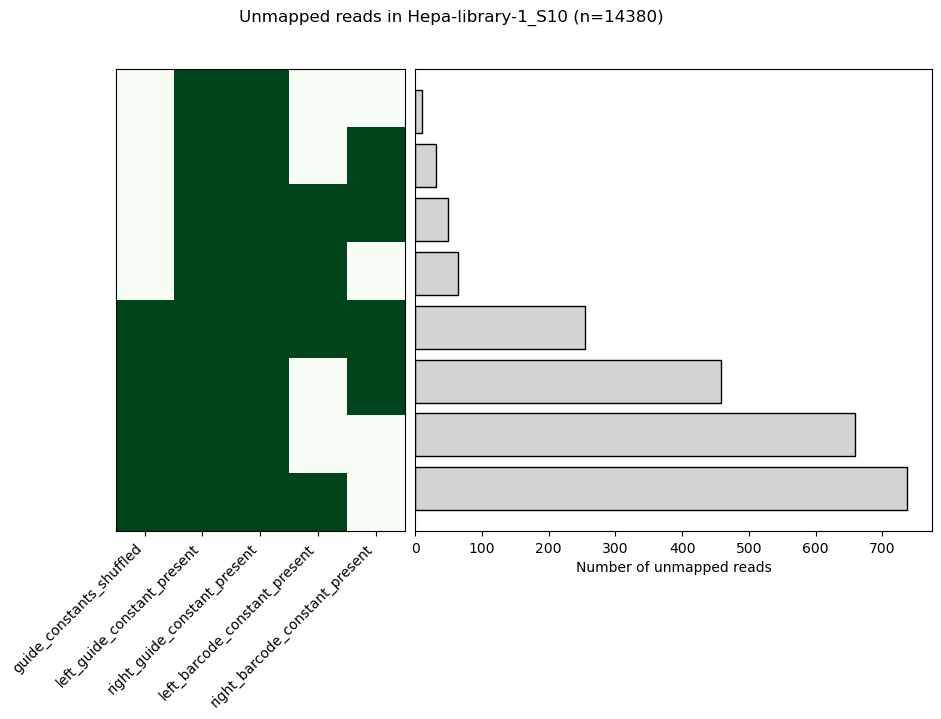

In [62]:
fig, axs = pl.subplots(1, 2, figsize=(12, 6), gridspec_kw={'wspace': -0.2})
ax = axs[0]
ax.imshow(info_cts.iloc[:, :-1], cmap='Greens')
ax.set_yticks([])
ax.set_xticklabels(['a'] + info_cts.columns[:-1].tolist(), rotation=45, ha='right')
ax = axs[1]
ax.barh(range(len(info_cts)), info_cts.iloc[:, -1], color='lightgrey', edgecolor='black')
ax.set_yticks([])
ax.set_xlabel('Number of unmapped reads')
pl.suptitle(f'Unmapped reads in {sample} (n={len(info_df)})')
pl.show()

In [54]:
info_cts.columns[:-1]

Index(['guide_constants_shuffled', 'left_guide_constant_present',
       'right_guide_constant_present', 'left_barcode_constant_present',
       'right_barcode_constant_present'],
      dtype='object')

In [34]:
info_cts

,guide_constants_shuffled,left_guide_constant_present,right_guide_constant_present,left_barcode_constant_present,right_barcode_constant_present,count
0,False,True,True,False,False,737
1,False,True,True,False,True,659
2,False,True,True,True,True,458
3,False,True,True,True,False,255
4,True,True,True,True,True,64
5,True,True,True,False,True,49
6,True,True,True,False,False,31
7,True,True,True,True,False,11


# Read structures

In [97]:
res = {}
i = 1000
for record in tqdm(SeqIO.parse(fastq_file, "fastq")):
    qual = record.letter_annotations["phred_quality"]
    seq = str(record.seq)
    
    if record.id in unmapped_reads:
        continue
    
    seq = seq.replace('CCGAGAATTCCA', 'CCGAGAATTCCA:')
    seq = seq.replace('GCTTTAAGGCCGG', ':GCTTTAAGGCCGG')
    seq = seq.replace('GGGGTTTGAAAC', 'GGGGTTTGAAAC:')
    seq = seq.replace('CAAGTAAACCCC', ':CAAGTAAACCCC')
    split = seq.split(':')
    if len(split) != 5:
        continue
    res[record.id] = [len(x) for x in split]
    if i <= 0:
        break
    i -= 1

0it [00:00, ?it/s]

In [98]:
df = pd.DataFrame(res, index=['constant1', 'guide', 'constant2', 'barcode', 'constant3']).T

constant1 length: mean=61.0, median=60.0, min=56, max=85
constant2 length: mean=29.7, median=21.0, min=14, max=58
constant3 length: mean=16.6, median=15.0, min=13, max=44


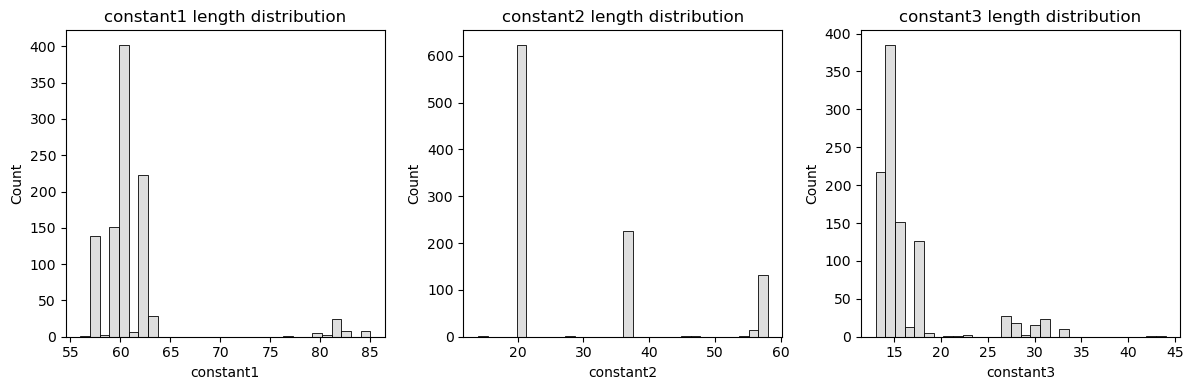

In [99]:
fig, axs = pl.subplots(1, 3, figsize=(12, 4))
axs = axs.flatten()
for i, key in enumerate(['constant1', 'constant2', 'constant3']):
    ax = axs[i]
    print(f"{key} length: mean={df[key].mean():.1f}, median={df[key].median()}, min={df[key].min()}, max={df[key].max()}")
    sns.histplot(data=df, x=key, bins=30, color='lightgrey', edgecolor='black', ax=ax)
    ax.set_title(f"{key} length distribution")
pl.tight_layout()
pl.show()

In [100]:
read_df

,sample,match_guide,mismatches_guide,effective_mismatches_guide,match_barcode,mismatches_barcode,effective_mismatches_barcode,guide_says,barcode_says,read_type
M02088:83:000000000-LY4KK:1:1101:10006:26895,Hepa-library-1_S10,ACTCACTTCATACAGCACGATCA,0.0,0.0,TGTTGGCAGACCGCA,0.0,0.0,INSR_8,INSR_8,matching_guide_and_barcode
M02088:83:000000000-LY4KK:1:1101:10006:5609,Hepa-library-1_S10,TCGTGATTCTTCCGCTCAGGGAC,0.0,0.0,CGTAGTTATACCTCT,1.0,1.0,NT_Control_rc_000644_NA,NT_Control_rc_000644_NA,matching_guide_and_barcode
M02088:83:000000000-LY4KK:1:1101:10015:4518,Hepa-library-1_S10,GAAGTCCTCACTGTCCACTGCAG,0.0,0.0,GGTGTTGGGAAGAAA,0.0,0.0,CIDEB_9,CIDEB_9,matching_guide_and_barcode
M02088:83:000000000-LY4KK:1:1101:10038:19406,Hepa-library-1_S10,CTGTGTGTAAACTTGCCACTGTG,0.0,0.0,TACCCTCTGTGAGTT,0.0,0.0,APOB_2,APOB_2,matching_guide_and_barcode
M02088:83:000000000-LY4KK:1:1101:10064:6262,Hepa-library-1_S10,AGAGACTTTGCTTGTGTCTCTGC,0.0,0.0,GTGTTCGCTCGGATT,0.0,0.0,APC_6,APC_6,matching_guide_and_barcode
...,...,...,...,...,...,...,...,...,...,...
M02088:83:000000000-LY4KK:1:2114:17135:28569,Hepa-library-3_S12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unmapped
M02088:83:000000000-LY4KK:1:2114:16445:28631,Hepa-library-3_S12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unmapped
M02088:83:000000000-LY4KK:1:2114:14404:28683,Hepa-library-3_S12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unmapped
M02088:83:000000000-LY4KK:1:2114:16693:28848,Hepa-library-3_S12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unmapped
